# 量子コンピューターの強みと弱み

このノートブックの目的は、量子コンピューターの強みと弱みを、その背景にある量子の概念とあわせて理解することです。強みと弱みは、探索問題に対する Grover のアルゴリズムを例にして、実際に動かして確認します。Grover のアルゴリズムそのものを学ぶことは目的ではなく、概念の効果を確かめるための題材です。

## 学ぶ内容

| 項目 | 背景にある量子の概念 | Grover の例で確認すること |
|---|---|---|
| 強み | 重ね合わせ、干渉 | 選択肢の数 $N$ に対して、古典は $N$ に比例する回数、量子は $\sqrt{N}$ に比例する回数で探索できる |
| 弱み | 測定、ノイズ、データの入出力 | 高速化の理論値と、実際に得られる結果との差 |

## 進め方

各項目で、最初に Grover を例にした実験の結果を確認します。次に、その結果の背景にある量子の概念を紹介し、概念が例の中でどう働いているかを説明します。

最後に、強みと弱みを踏まえて、この高速化が自分の問題で実際に得になるかを判断する観点を整理します。

## 強みの確認:探索に必要な回数

量子コンピューターが、古典コンピューターよりどれだけ少ない手順で解けるかを、探索問題で確かめます。探索問題は、量子の強みを最も単純な形で確認できる例です。

### 課題: 当たりの箱を探す

$N$ 個の箱が並んでいて、そのうち1つだけが当たりです。どれが当たりかは、箱を開けて中を確かめるまで分かりません。箱の並びにヒントもありません。

![N個の箱が並び、そのうち1つだけが当たり。中身は開けてみるまで分からない](./resources/ch02-unstructured-search.svg)

このとき、当たりを見つけるまでに、箱を何回開けることになるでしょうか。

ヒントがないので、1つずつ順に開けていくしかありません。運が良ければ1回目で当たりますし、運が悪ければ最後の1個まで開けることになります。平均すると、およそ半分の箱を開けた頃に当たります。実際に、普通のPythonで確かめてみましょう。

In [1]:
import random


def count_boxes_opened(n_boxes, rng):
    """当たりの箱をランダムな順に1つずつ開けて、見つかるまでに開けた回数を返す。"""
    winner = rng.randrange(n_boxes)
    order = rng.sample(range(n_boxes), n_boxes)
    return order.index(winner) + 1


rng = random.Random(12345)
TRIALS = 10000

for n_boxes in (4, 8, 16):
    average = sum(count_boxes_opened(n_boxes, rng) for _ in range(TRIALS)) / TRIALS
    print(f"箱が{n_boxes:>2}個: 平均 {average:.2f} 回で当たりが見つかった")

箱が 4個: 平均 2.50 回で当たりが見つかった
箱が 8個: 平均 4.50 回で当たりが見つかった
箱が16個: 平均 8.47 回で当たりが見つかった


箱の数が2倍になると、開ける回数もほぼ2倍になります。箱が $N$ 個のとき、平均で約 $(N+1)/2$ 回です。箱の中身に手がかりがない以上、古典のコンピューターにはこれより良い方法がありません。

### 量子コンピューターでやるとどうなるか

同じ探索を、量子コンピューター(のシミュレーター)でやってみます。**Groverのアルゴリズム**という方法を使います。仕組みは結果を確認したあとで説明するので、まずは結果だけを見てください。

次のセルは準備です。中身は読み飛ばして、実行だけしてください。

In [2]:
import math

from qiskit import QuantumCircuit
from qiskit.circuit.library import ZGate
from qiskit.primitives import StatevectorSampler
from qiskit.quantum_info import Statevector


def make_oracle(n):
    """|11...1> の符号だけを反転する(多重制御Zゲート)。"""
    qc = QuantumCircuit(n, name="oracle")
    qc.append(ZGate().control(n - 1), range(n))
    return qc


def make_diffuser(n):
    """平均についての反転 U_s = 2|s><s| - 1。"""
    qc = QuantumCircuit(n, name="diffuser")
    qc.h(range(n))
    qc.x(range(n))
    qc.append(ZGate().control(n - 1), range(n))
    qc.x(range(n))
    qc.h(range(n))
    return qc


def make_grover(n, iterations, measure=True):
    """n量子ビットのGroverの回路。オラクルと拡散操作を iterations 回繰り返す。"""
    oracle, diffuser = make_oracle(n), make_diffuser(n)
    qc = QuantumCircuit(n)
    qc.h(range(n))
    for _ in range(iterations):
        qc.compose(oracle, inplace=True)
        qc.compose(diffuser, inplace=True)
    if measure:
        qc.measure_all()
    return qc


def optimal_iterations(n):
    """成功確率が最大になる繰り返し回数。"""
    return round(math.pi / 4 * math.sqrt(2**n) - 0.5)

In [3]:
SHOTS = 1000
sampler = StatevectorSampler(seed=12345)

rows = []
for n in (2, 3, 4):
    N = 2**n
    k = optimal_iterations(n)
    target = "1" * n

    # 厳密な正解確率(状態ベクトルから計算)
    exact = Statevector(make_grover(n, k, measure=False)).probabilities_dict().get(target, 0.0)

    # 1000ショットでの実測
    counts = sampler.run([make_grover(n, k)], shots=SHOTS).result()[0].data.meas.get_counts()
    measured = counts.get(target, 0) / SHOTS

    rows.append((N, (N + 1) / 2, k, exact, measured))

print("箱の数  古典の平均  Groverの回数  当たりを引く確率(理論)  当たりを引く確率(実測)")
for N, classical, k, exact, measured in rows:
    print(f"{N:>6} {classical:>11.1f} {k:>12} {exact:>22.1%} {measured:>22.1%}")

箱の数  古典の平均  Groverの回数  当たりを引く確率(理論)  当たりを引く確率(実測)
     4         2.5            1                 100.0%                 100.0%
     8         4.5            2                  94.5%                  95.5%
    16         8.5            3                  96.1%                  97.1%


### 結果を読む

| 箱の数 $N$ | 古典(平均) | 量子(Grover) | 当たりを引く確率 |
|---|---|---|---|
| 4 | 2.5 回 | 1 回 | 100% |
| 8 | 4.5 回 | 2 回 | 約95% |
| 16 | 8.5 回 | 3 回 | 約96% |

- 古典は、箱の数が2倍になると開ける回数もほぼ2倍になります。
- 量子は、箱の数が4倍(4→16)になっても、回数は 1 → 3 回にしか増えていません。約 $\sqrt{N}$ 倍で済みます。
- しかも、当たりを引く確率はほぼ確実です。

箱が増えるほど、この差は広がります。これが量子コンピューターの **強み** です。

> ここで言う「Groverの回数」は、「箱の中身を確かめる操作」を何回行うかを数えたものです。回数が少なくて済むのは確かですが、1回あたりの操作の重さは、まだ比べていません。それは、制約を見るときに確かめます。

それでは、量子コンピューターのどのような性質が、この差を生んでいるのでしょうか。次の節で、背景にある概念を紹介します。

## 強み:背景にある量子の概念

先ほどの結果は、量子ビットが古典のビットにない性質を持つために得られたものです。この性質のうち、次の2つが背景にあります。

- **重ね合わせ:** $n$ 個の量子ビットの状態は、$2^n$ 通りの状態それぞれに **振幅** という数を割り当てた形で表される。振幅は符号を持つ数で、その **2乗が、測定でその状態が得られる確率** になる。古典の $n$ ビットは、ある瞬間には $2^n$ 通りのうち1通りに決まっている。
- **干渉:** 操作によって、各状態に割り当てられた数が強め合ったり打ち消し合ったりする。この性質を使うと、求める答えを得る確率を高め、それ以外の確率を下げられる。

注意すべき点は、重ね合わせが「$2^n$ 通りをすべて試した結果を得られる」ことを意味しない点です。測定すると、得られる結果は1つだけです。量子コンピューターの強みは、重ね合わせの状態に干渉を起こして、**答えを得る確率を高める**ことにあります。

この2つが、先ほどの探索の中でどのように働いているかを、次の節で確認します。

## 重ね合わせと干渉の働き

先ほどの結果は、重ね合わせと干渉を、次のように使うことで得られています。この手順は Grover のアルゴリズムと呼ばれます。

1. **重ね合わせ:** すべての箱の振幅を等しくした状態から始める。この時点では、どの箱を引き当てる確率も同じで、当てずっぽうに選ぶのと変わらない。
2. **目印をつける(オラクル):** 当たりの箱の振幅の符号だけを反転する。箱の中身を読み出すのではなく、当たりの箱に目印をつける操作にあたる。
3. **干渉を起こす(拡散操作):** 目印のついた箱の振幅を強め合わせ、ほかの箱の振幅を打ち消し合わせる。当たりの箱を引き当てる確率が高まる。
4. **2 と 3 を繰り返す:** 約 $\sqrt{N}$ 回の繰り返しで、当たりの箱を引き当てる確率がほぼ1になる。

古典計算では、箱を1つ確かめるたびに、候補が1つ減るだけです。量子計算では、すべての箱の振幅を、1回の操作でまとめて変化させます。必要な回数が $N$ ではなく $\sqrt{N}$ で済むのは、このためです。

以降で、2 と 3 の操作を、数式と回路で確認します。

### オラクル

量子コンピューターで探索するには、まず箱に番号をつけて、量子ビットの状態として表します。箱の数が $N=2^n$ なら、番号を $n$ ビットの2進数 $x \in \{0,1\}^n$ で書けるので、$n$ 量子ビットの基底状態 $|x\rangle$ が1つの箱に対応します。

**オラクル** は、「この箱は当たりか」を判定する装置です。ただし、中身を読み出して答えを返すのではなく、**当たりの箱の符号だけを反転します**。ほかの箱には何もしません。

次の図は、箱が4つ($N=4$)で、箱 11 が当たりの場合です。

![オラクルは当たりの箱の符号だけを反転する](./resources/ch02-oracle.svg)

この動きを式で書くと、次のようになります。$f(x)$ は、当たりなら 1、ハズレなら 0 を返す関数です。

$$ U_w |x\rangle = (-1)^{f(x)} |x\rangle $$

ハズレ ($f(x)=0$) なら $(-1)^0 = +1$ で何も変わらず、当たり ($f(w)=1$) なら $(-1)^1 = -1$ で符号が反転します。

> オラクルは、箱の中身を読み出していません。当たりの箱に「－」のしるしをつけただけで、**まだ誰も、どれが当たりかを知りません**。このしるしを足がかりに、次の「振幅の変化」で当たりの確率を大きくしていきます。

### 振幅の変化

それぞれの箱には振幅が割り当てられていて、その2乗が、その箱を測定で引き当てる確率です。最初は、どの箱も同じ振幅 $1/\sqrt{N}$ から始めます。

$$ |s\rangle = \frac{1}{\sqrt{N}} \sum_{x=0}^{N-1} |x\rangle $$

この状態をそのまま測ると、当たりを引く確率は $1/N$ です。これでは、古典で当てずっぽうに選ぶのと同じです。そこで、当たりの振幅だけを少しずつ大きくする操作を繰り返します。1回の繰り返しは、次の2つの操作でできています。

1. **オラクル $U_w$:** 当たりの符号を反転する。平均の振幅が少し下がる。
2. **拡散操作 $U_s = 2|s\rangle\langle s| - 1$:** 平均の振幅を軸に、すべての振幅を反転する。符号が負になっていた当たりの振幅が、大きく増える。

箱が8個の場合に、振幅がどう変わるかを見てみましょう。棒の高さが振幅、赤い破線が平均です。

![オラクルで当たりが負になり、拡散操作で当たりの振幅が大きく伸びる](./resources/ch02-amplitude.svg)

ポイントは、拡散操作が「平均を軸に反転する」ことです。各棒について、**平均からの距離はそのままで、上と下が入れ替わります**。

- 当たりは、② でオラクルに負にされたので、平均より **大きく下** にありました。反転すると、同じだけ平均より **大きく上** に跳ね上がります。
- ハズレは、平均より **少し上** にありました。反転すると、同じだけ平均より **少し下** に移ります。そのため、ハズレの振幅は小さくなります。

確率の合計は、いつも 100% です。当たりの振幅が伸びると、その分、ハズレの確率が減ります。これが、1回の繰り返しで起きていることです。

この1回で、当たりを引く確率は 12.5% から約 78% に増えました。同じ操作をもう一度行うと約 94.5% になり、$N=8$ では2回で、ほぼ確実に当たりを引けます。一般に、約 $\sqrt{N}$ 回の繰り返しで、ほぼ確実に当たりが得られます。

![Groverのアルゴリズムの流れ。重ね合わせ、オラクルと拡散操作の繰り返し、測定](./resources/ch02-grover-flow.svg)

### Qiskit で実装する: まず N=4(2量子ビット)

まず、2量子ビットで $|11\rangle$ を探します。$N=4$ です。

当たり $|11\rangle$ の符号だけを反転するオラクルは、CZ ゲートそのものです。

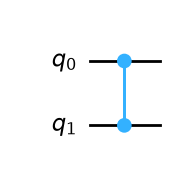

In [4]:
from qiskit import QuantumCircuit

oracle = QuantumCircuit(2)
oracle.cz(0, 1)
oracle.draw("mpl")

次に、平均についての反転(拡散操作)の回路を作ります。$U_s = 2|s\rangle\langle s| - 1$ は、Hゲート、Xゲート、CZ(ここでは H・CX・H) を組み合わせて実装できます。

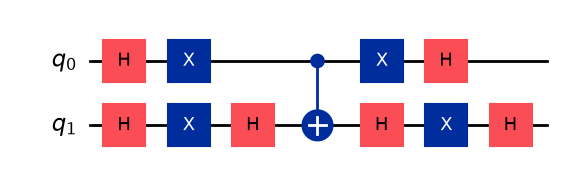

In [5]:
diffuser = QuantumCircuit(2)
diffuser.h([0, 1])
diffuser.x([0, 1])
diffuser.h(1)
diffuser.cx(0, 1)
diffuser.h(1)
diffuser.x([0, 1])
diffuser.h([0, 1])
diffuser.draw("mpl")

最初に均一な重ね合わせ状態を作り、オラクルと拡散操作を並べ、最後に測定します。$N=4$ では、繰り返しは1回です。

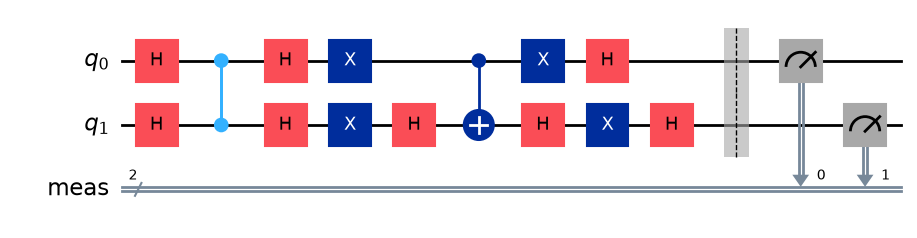

In [6]:
grover4 = QuantumCircuit(2)
grover4.h([0, 1])
grover4.compose(oracle, inplace=True)
grover4.compose(diffuser, inplace=True)
grover4.measure_all()
grover4.draw("mpl")

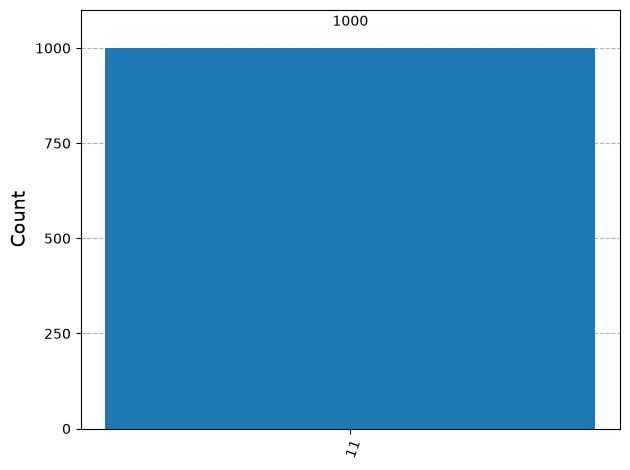

In [7]:
from qiskit.primitives import StatevectorSampler
from qiskit.visualization import plot_histogram

sampler = StatevectorSampler(seed=12345)
counts = sampler.run([grover4], shots=1000).result()[0].data.meas.get_counts()
plot_histogram(counts)

### 箱が増えても同じ作りで動く

ここまでの $N=4$ の回路は、箱の数が増えても、同じ作りのまま広げられます。冒頭で実行した準備セル(`make_grover` など)は、それを $n$ 量子ビット ($N=2^n$) の関数にまとめたものです。

- **オラクル:** 当たりを $|11\cdots1\rangle$ に決めると、「全部のビットが1のときだけ符号を反転する」多重制御Zゲートになります。
- **拡散操作:** その前後を H と X で挟んだ形です。
- **繰り返し回数:** $k \approx \frac{\pi}{4}\sqrt{N}$ に最も近い整数にします。

箱の数を増やすと、どれだけ繰り返すのが最適かを、次のセルで確かめます。

In [8]:
for n in (2, 3, 4):
    print(f"箱が{2**n:>2}個: 最適な繰り返し回数 k = {optimal_iterations(n)}")

箱が 4個: 最適な繰り返し回数 k = 1
箱が 8個: 最適な繰り返し回数 k = 2
箱が16個: 最適な繰り返し回数 k = 3


## 強みの根拠:状態の大きさともつれ

ここまでの実験は、古典コンピューター(のシミュレーター)で動かしました。量子コンピューターが古典より速いと言えるのは、なぜでしょうか。

### 状態を表すのに必要な数

$n$ 量子ビットの一般の状態は、$2^n$ 個の振幅で表されます。古典コンピューターで、この状態をそのまま記憶するには、振幅1つあたり16バイト(複素数を128ビットで保持した場合)が必要です。

| 量子ビット数 $n$ | 状態を表す振幅の数 | 必要なメモリ |
|---|---|---|
| 10 | 1,024 | 約 16 KiB |
| 20 | 約 100万 | 約 16 MiB |
| 30 | 約 10億 | **16 GiB** |
| 40 | 約 1兆 | 約 16 TiB |

量子ビットが10個増えるごとに、必要なメモリは約1,000倍になります。30量子ビットで16 GiB、40量子ビットでは、一般的な計算機のメモリを大きく超えます。

ただし、すべての状態がこれほど大きな記憶を必要とするわけではありません。次の節で確認します。

### もつれのない状態は小さく表せる

量子ビットごとに独立な状態、つまり **積状態** であれば、量子ビット1個あたり2つの振幅を記憶するだけで済みます。$n$ 量子ビットで $2n$ 個です。30量子ビットでも、960バイトで足ります。

| 状態の種類 | 30量子ビットを表すのに必要なメモリ |
|---|---|
| 一般の状態 | 16 GiB |
| 積状態 | 960 バイト |

積状態として書けない状態を、**もつれた状態** と呼びます。量子ビットどうしが独立でなくなり、全体の状態を $2^n$ 個の振幅で持つ必要が出てきます。

つまり、重ね合わせの状態であっても、もつれがなければ、古典コンピューターで小さく表せます。古典コンピューターに対して指数的な高速化を得るには、計算の途中で、もつれが量子ビット数とともに大きくなる必要があります。もつれが小さい間は、古典コンピューターで効率よくシミュレートできることが知られています。

### Grover の探索で、もつれはどう現れるか

箱が4つ($N=4$)の探索について、各段階の状態が積状態かどうかを調べます。2量子ビットの状態を $2\times2$ の表に並べたとき、その行列式が0なら積状態です。

In [9]:
from qiskit.quantum_info import Statevector

# N=4 の各段階の状態を作る
start = QuantumCircuit(2)
start.h([0, 1])
after_h = Statevector(start)
after_oracle = after_h.evolve(oracle)
after_diffuser = after_oracle.evolve(diffuser)

for name, state in [("最初(H の後)", after_h), ("オラクルの後", after_oracle), ("拡散操作の後", after_diffuser)]:
    a = state.data.reshape(2, 2)
    det = round(float((a[0, 0] * a[1, 1] - a[0, 1] * a[1, 0]).real), 9) + 0.0  # 0 なら積状態。丸めて -0.00 の表示を避ける
    amps = [round(float(x.real), 2) + 0.0 for x in state.data]
    verdict = "積状態" if abs(det) < 1e-9 else "もつれている"
    print(f"{name}")
    print(f"  振幅 (|00>, |01>, |10>, |11>): {amps}")
    print(f"  行列式: {det:.2f}  →  {verdict}")

最初(H の後)
  振幅 (|00>, |01>, |10>, |11>): [0.5, 0.5, 0.5, 0.5]
  行列式: 0.00  →  積状態
オラクルの後
  振幅 (|00>, |01>, |10>, |11>): [0.5, 0.5, 0.5, -0.5]
  行列式: -0.50  →  もつれている
拡散操作の後
  振幅 (|00>, |01>, |10>, |11>): [0.0, 0.0, 0.0, -1.0]
  行列式: 0.00  →  積状態


結果を読みます。

- **最初と最後は積状態** (行列式が0)。最後の状態は $-|11\rangle$ で、全体の符号が負になっていますが、確率は振幅の2乗なので、測定結果には影響しません。
- **オラクルの直後だけ、もつれた状態** (行列式が0でない)。オラクルは「$|11\rangle$ の符号だけを反転する」操作で、$(|00\rangle+|01\rangle+|10\rangle-|11\rangle)/2$ という、量子ビットごとの積には書けない状態を作ります。拡散操作が、これを再び1つの状態に戻します。

この例は箱が4つの場合に限った話です。箱が8個、16個と増えると、拡散操作のあとも、もつれは完全には消えません。一般に、Grover のアルゴリズムは、繰り返しの途中でもつれた状態を通ります。

#### 補足:もつれが重要である理由

純粋状態の量子計算が、古典に対して指数的な高速化を得るには、もつれが問題の大きさとともに増える必要があります。もつれが小さければ、古典コンピューターで効率よくシミュレートできます(Vidal, *Phys. Rev. Lett.* 91, 147902 (2003) / Jozsa and Linden, *Proc. R. Soc. A* 459, 2011 (2003))。

もつれを作るのは、2つの量子ビットにまたがるゲートです。このゲートは、1つの量子ビットだけに作用するゲートより、誤りが大きくなるのが一般的です。この点は、後の「弱み」の節で、ノイズの影響として確認します。

## 弱み:理論値と実際の結果の差

ここまでで、量子コンピューターは、探索に必要な回数を $N$ から $\sqrt{N}$ に減らせることを確認しました。この値は、理想的な量子コンピューターを仮定した理論値です。実際に使うときには、次の3つの制約があります。

| 制約 | 内容 |
|---|---|
| 測定 | 1回の実行で得られる結果は1つだけ。途中の状態は見られない |
| ノイズ | 操作のたびに誤りが入り、状態が壊れる |
| データの入出力 | 問題のデータを量子の操作として組み込むのに、手間がかかる |

それぞれを、同じ探索の例で確認します。

### 測定:1回の実行で得られる結果は1つだけ

量子コンピューターの回路を1回実行して測定すると、得られる結果は1つだけです。これまでの実験で「当たりを引く確率は約96%」と書いてきたのは、回路を1000回繰り返して実行し、そのうち約96%の回で当たりが得られた、という意味です。

1回だけ実行したとき、何が得られるかを確かめます。箱が16個($N=16$)の探索を、1回ずつ20回実行します。繰り返しの回数は、最適な3回と、それより1回多い4回の2通りで比べます。

In [10]:
def sample_20_times(iterations):
    """n=4 (N=16) の回路を20回実行し、1回ごとの結果を並べて返す。"""
    circuit = make_grover(4, iterations)
    job = StatevectorSampler(seed=12345).run([circuit], shots=20)
    # 各ショットの結果を、実行した順に1つずつ取り出す
    return [str(bits) for bits in job.result()[0].data.meas.get_bitstrings()]


for iterations in (optimal_iterations(4), optimal_iterations(4) + 1):
    results = sample_20_times(iterations)
    print(f"繰り返し {iterations} 回: 当たり(1111)が得られた回数 {results.count('1111')} / 20")
    print("  ", " ".join(results[:10]))
    print("  ", " ".join(results[10:]))

繰り返し 3 回: 当たり(1111)が得られた回数 20 / 20
   1111 1111 1111 1111 1111 1111 1111 1111 1111 1111
   1111 1111 1111 1111 1111 1111 1111 1111 1111 1111
繰り返し 4 回: 当たり(1111)が得られた回数 11 / 20
   1000 1011 1111 1111 1110 1011 1111 0110 1111 1111
   1000 1111 1111 0011 1111 1111 1111 1011 1111 0111


結果を読みます。

- **最適な回数(3回)では、20回すべてで当たり** が得られました。理論値は約96%なので、まれに外れることもありますが、ほぼ確実に当たります。
- **1回多い4回では、20回中11回** しか当たりませんでした。理論値の約58%と整合します。残りの9回は、当たり以外の別の箱が得られています。

この実験から、測定について次の3点が分かります。

1. **1回の実行で得られるのは、1つの結果だけ** です。その結果が当たりかどうかは、箱の中身を実際に確認する(検算する)まで分かりません。
2. **途中の状態は見られません。** 測定すると状態が壊れるので、「そろそろ当たりが見えてきた」と途中で確かめて止めることはできません。繰り返しの回数は、事前に計算で決める必要があります。
3. **最適な回数を超えて繰り返すと、悪くなります。** 古典の探索は、続けるほど見つかる確率が上がります。Grover の探索は、続けるほど良くなるとは限りません。

3つ目の点を、繰り返しの回数ごとに見ます。当たりを引く確率(理論値)は、次のように変化します。

![繰り返しの回数と、当たりを引く確率。最適な回数を超えると下がり、さらに繰り返すと再び上がる](./resources/ch02-iterations.svg)

箱が16個の場合、当たりを引く確率は、3回の繰り返しで約96%と最大になります。4回に増やすと約58%、6回では約2%まで下がります。さらに繰り返すと、9回で約99%に戻ります。繰り返しの回数に対して、確率は周期的に増減します。

古典の探索は、続けるほど見つかる確率が単調に上がるのと対照的です。量子の探索では、**最適な回数を事前に計算して、そこで止める** 必要があります。測定すると状態が壊れるので、途中で確かめて止めることはできません。

### ノイズ:操作のたびに誤りが入る

ここまでのシミュレーションは、誤りのない理想的な量子コンピューターを仮定していました。実際の量子コンピューターでは、ゲートを実行するたびに、わずかな誤りが入ります。特に、もつれを作る2量子ビットゲート(CX ゲート)は、1量子ビットゲートより誤りが大きくなるのが一般的です。

誤りが入ると、状態が壊れていき、当たりを引く確率が下がります。回路が大きくなるほど、ゲートの数が増えるので、影響は大きくなります。

箱の数を増やしながら、ノイズありのシミュレーターで探索の成功率を測ります。誤りの大きさは、この教材で置いた仮定値です。実機の測定値ではありません。

| ゲート | 誤りの確率(仮定値) |
|---|---|
| 1量子ビットゲート | 0.1% |
| 2量子ビットゲート (CX) | 1% |

回路は、これらのゲートだけを使う形に分解してから実行します。

In [11]:
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

# この教材で置いた仮定値(実機の測定値ではない)
ERROR_1Q = 0.001
ERROR_2Q = 0.01

noise_model = NoiseModel()
noise_model.add_all_qubit_quantum_error(depolarizing_error(ERROR_1Q, 1), ["sx", "x"])
noise_model.add_all_qubit_quantum_error(depolarizing_error(ERROR_2Q, 2), ["cx"])
noisy_backend = AerSimulator(noise_model=noise_model)
BASIS_GATES = ["cx", "rz", "sx", "x"]

print("箱の数  CXの数  理想の成功率  ノイズありの成功率")
for n in (2, 3, 4, 5, 6):
    k = optimal_iterations(n)
    decomposed = transpile(make_grover(n, k), basis_gates=BASIS_GATES, optimization_level=1, seed_transpiler=12345)
    ideal = Statevector(make_grover(n, k, measure=False)).probabilities_dict().get("1" * n, 0.0)
    counts = noisy_backend.run(decomposed, shots=2000, seed_simulator=12345).result().get_counts()
    noisy = counts.get("1" * n, 0) / 2000
    print(f"{2**n:>6} {decomposed.count_ops().get('cx', 0):>7} {ideal:>12.1%} {noisy:>18.1%}")

箱の数  CXの数  理想の成功率  ノイズありの成功率
     4       2       100.0%              98.2%
     8      24        94.5%              76.9%
    16      84        96.1%              47.6%
    32     288        99.9%              11.1%
    64    1008        99.7%               1.6%


結果を読みます。

- **箱が増えるほど、成功率が大きく下がります。** 理想的な量子コンピューターでは、どの箱の数でも成功率は94%以上です。ノイズがあると、箱が16個で約48%、32個で約11%に下がります。
- **箱が64個では、成功率が約1.6%** です。これは、64個からでたらめに1つ選んだときの当たる確率($1/64 \approx 1.6\%$)とほぼ同じです。ノイズのせいで、量子の探索が、当てずっぽうと変わらなくなっています。
- **原因は、CX ゲートの数です。** 箱が増えるほど、必要な繰り返しの回数と、1回の繰り返しに含まれるゲートの数がともに増え、CX の総数は2個から1008個まで増えます。誤りは、ゲートが1つ増えるたびに積み重なります。

理論上は $\sqrt{N}$ 回で済むという強みは、ノイズがあると、回路が大きくなるにつれて打ち消されていきます。

> ここでのノイズの大きさは、この教材で置いた仮定値(1量子ビットゲート0.1%、2量子ビットゲート1%)です。実機の誤りの大きさは、機種や時期によって異なります。ノイズの原因と、それを抑える方法は、「実機の結果はなぜ壊れるのか」の章で扱います。

### データの入出力:オラクルを作るコスト

ここまでの探索では、当たりを $|11\cdots1\rangle$ に決めていました。この場合、オラクルは、多重制御Zゲート1つで書けます。実際の問題では、当たりの箱が、問題のデータによって決まります。たとえば、「データの表の中から、条件に合う行を探す」ような場合です。

条件を数式や関数として短く書ける問題と、データの表を参照して決まる問題とでは、オラクルを作るコストが大きく違います。

#### 繰り返し1回あたりのコスト

箱の数を増やしたとき、1回の繰り返し(オラクルと拡散操作)に必要な CX ゲートの数を数えます。

In [12]:
print("箱の数  1回の繰り返しに必要な CX の数")
for n in range(2, 9):
    one_iteration = transpile(make_grover(n, 1, measure=False), basis_gates=BASIS_GATES, optimization_level=1, seed_transpiler=12345)
    print(f"{2**n:>6} {one_iteration.count_ops().get('cx', 0):>22}")

箱の数  1回の繰り返しに必要な CX の数
     4                      2
     8                     12
    16                     28
    32                     72
    64                    168
   128                    248
   256                    360


1回の繰り返しに必要な CX の数は、箱が増えると大きくなります。ただし、この回路は「当たりを $|11\cdots1\rangle$ に決めた」特別な場合です。

#### データの表からオラクルを作る

現実の問題では、当たりの箱は、データの表から決まります。たとえば、$N$ 行の表があり、ある値に等しい行を探す問題です。このとき、オラクルを作るには、表の各行について「この行が条件に合うか」を調べ、合う行の箱に目印をつける回路を、回路に書き込まなければなりません。

次のコードは、表を1行ずつ読んで、条件に合う行だけを反転するオラクルを作ります。読んだ行の数も数えます。

In [13]:
import random

from qiskit.quantum_info import Operator


def oracle_from_table(table, target):
    """表を1行ずつ読み、値が target に等しい行の箱だけ符号を反転するオラクルを作る。"""
    n = int(math.log2(len(table)))
    circuit = QuantumCircuit(n)
    rows_read = 0
    for box, value in enumerate(table):
        rows_read += 1  # 表の行を1つ読む
        if value == target:
            zeros = [i for i in range(n) if not (box >> i) & 1]
            if zeros:
                circuit.x(zeros)
            circuit.append(ZGate().control(n - 1), range(n))
            if zeros:
                circuit.x(zeros)
    return circuit, rows_read


rng = random.Random(12345)
print("箱の数  表を読んだ回数  古典の平均探索回数  Groverの繰り返し回数")
for n in (2, 3, 4, 8, 10):
    N = 2**n
    table = list(range(N))
    rng.shuffle(table)
    circuit, rows_read = oracle_from_table(table, target=N // 3)
    if n <= 4:  # 小さい場合は、条件に合う箱だけが反転されることを確かめる
        flipped = [i for i, v in enumerate(Operator(circuit).data.diagonal()) if v.real < 0]
        assert flipped == [table.index(N // 3)]
    print(f"{N:>6} {rows_read:>13} {(N + 1) / 2:>17.1f} {optimal_iterations(n):>19}")

箱の数  表を読んだ回数  古典の平均探索回数  Groverの繰り返し回数
     4             4               2.5                   1
     8             8               4.5                   2
    16            16               8.5                   3
   256           256             128.5                  12
  1024          1024             512.5                  25


結果を読みます。

- **1回の繰り返しに必要な CX の数は、箱が増えるほど増えます。** 箱が4個で2個、16個で28個、256個で360個です。回数が $\sqrt{N}$ に減っても、1回あたりの回路が大きくなるので、実際に実行する操作の量は、回数の減り方ほどには減りません。
- **表からオラクルを作るには、表の全行を読む必要があります。** 表を読んだ回数は、箱の数 $N$ とちょうど同じです。古典の探索は、平均で約 $N/2$ 回、箱を確かめれば足ります。つまり、**オラクルを作るために表を読む回数だけで、すでに古典の探索回数を上回っています。**

2つ目が重要です。Grover の探索が $\sqrt{N}$ 回で済むのは、オラクルがすでに回路として与えられている場合です。オラクルを作るのに $N$ 回かかるなら、全体では $N$ に比例するコストがかかり、高速化の利点は打ち消されます。

この違いが、Grover の探索が向く問題と向かない問題を分けます。

| 問題の種類 | オラクルの作り方 | 高速化の利点 |
|---|---|---|
| 条件を関数として短く書ける(たとえば、論理式を満たす入力を探す) | 条件を回路として、小さく書ける | 保たれる |
| 古典のデータの表から探す | 表の全行を読み込んで、回路に組み込む必要がある | 打ち消されうる |

どちらの種類の問題に当たるかを見分けることが、量子コンピューターを使うかどうかを判断する、最初の手がかりになります。

なお、この表の「保たれる」は、ここまでの実験で確かめたことではありません。実験で確かめたのは、「当たりを固定した単純なオラクルは小さく書ける」ことと、「表から作るオラクルは全行の読み込みが必要」なことの2点です。条件を関数として書ける実際の問題(論理式を満たす入力を探す問題など)で、どの程度のオラクルが必要になるかは、第3章のサンプルユースケースで扱います。

## 強みと弱みから、適用の判断へ

ここまでで、探索問題を例に、量子コンピューターの強みと弱みを確認しました。

| | 確認したこと |
|---|---|
| 強み | 探索に必要な回数が、$N$ から約 $\sqrt{N}$ に減る。背景には、重ね合わせと干渉がある |
| 弱み:測定 | 1回の実行で得られる結果は1つ。繰り返しの回数を事前に決める必要があり、超えると確率が下がる |
| 弱み:ノイズ | 回路が大きくなるほど成功率が下がる。この教材の仮定では、箱が64個で、当てずっぽうと同じ水準になった |
| 弱み:データの入出力 | 表のデータからオラクルを作るには、全行の読み込みが必要で、$N$ に比例する手間がかかる |

量子コンピューターの高速化が、自分の問題で得になるかは、次の問いで判断できます。

1. **回数が減るのは、何の回数か。** 「判定」の回数が減っても、判定の回路を作る手間や、1回あたりの回路の大きさが増えれば、全体では得になりません。
2. **問題のデータは、回路として小さく書けるか。** 条件が式や関数で書けるのか、大量の表を読み込む必要があるのかで、オラクルの大きさが大きく変わります。
3. **必要な回路の大きさは、今のノイズに耐えられるか。** 理論上の回数が少なくても、回路が大きければ、ノイズで結果が壊れます。
4. **結果を、自分で検算できるか。** 1回の実行で得られるのは1つの結果で、それが正しいかは、別に確認する必要があります。

これらは、探索問題に限らず、量子コンピューターの適用を検討するときの共通の観点です。次の章では、これらの観点を使って、領域ごとの具体的な問題(最適化、化学、機械学習、暗号)を見ていきます。

### この章で扱わなかったこと

- **ノイズの原因と対策:** なぜ誤りが入るのか、どう抑えるのか、将来どう解決されるのかは、「実機の結果はなぜ壊れるのか」の章で扱います。
- **実機での実行:** この章は、すべてシミュレーターで実行しました。実機で動かす手順は、「回路を実機で動かす」の章で扱います。

## 実行環境

このノートブックの実行に使ったライブラリのバージョンです。

In [ ]:
import ast
import platform
from importlib.metadata import packages_distributions, version

# このノートブックが import している Qiskit 系のパッケージだけを表示する
used = set()
for source in In:
    try:
        nodes = ast.walk(ast.parse(source))
    except SyntaxError:  # ! や % で始まるセルは読み飛ばす
        continue
    for node in nodes:
        if isinstance(node, ast.Import):
            tops = [a.name.split(".")[0] for a in node.names]
        elif isinstance(node, ast.ImportFrom) and node.level == 0:
            tops = [node.module.split(".")[0]]
        else:
            continue
        for top in tops:
            if top.startswith("qiskit"):
                used.update(packages_distributions().get(top, []))

print(f"{'python':<24} {'.'.join(platform.python_version().split('.')[:2])}")
for name in sorted(used):
    print(f"{name:<24} {version(name)}")